# Perceptron Trick — How to Train a Perceptron

---

## 1. Geometric Intuition

Start with randomly initialized weights, which define a random decision boundary line. This line will likely misclassify many points initially.

The training loop does the following:

1. Pick a **misclassified point**.
2. **Nudge** the line toward that point so it rotates/shifts to classify it correctly.
3. Repeat until all points are correctly classified (or the maximum number of epochs is reached).

The line gradually rotates and shifts until it finds a valid separating boundary.

---

## 2. Understanding Regions — Which Side of the Line?

For a line equation **ax + by + c = 0**, plugging any point (x, y) into the left-hand side tells you which region it falls in:

| Result | Region |
|---|---|
| `ax + by + c > 0` | Positive region |
| `ax + by + c < 0` | Negative region |
| `ax + by + c = 0` | On the line |

**Example:** Line `2x + 3y + 5 = 0`
- Point (1, 1): `2(1) + 3(1) + 5 = 10 > 0` → positive region
- Point (-5, -5): `2(-5) + 3(-5) + 5 = -20 < 0` → negative region

> Changing the sign of all coefficients (a, b, c) flips which side is positive and which is negative.

---

## 3. How Changing Weights Moves the Line

Each weight parameter controls a different geometric transformation:

| Parameter | Effect |
|---|---|
| `c` (bias) | Shifts the line **parallel to itself** — moves it up or down without changing its angle |
| `a` (weight of x) | Rotates the line around the **y-axis** |
| `b` (weight of y) | Rotates the line around the **x-axis** |

By combining updates to all three, the perceptron can move and rotate the line in any direction needed to fix misclassified points.

---

## 4. The Perceptron Trick Rule

Given a misclassified point with features (x₁, x₂) and true label y ∈ {0, 1}:

**Case 1 — Negative point in the positive region** (predicted 1, actual 0):
$$w_{\text{new}} = w_{\text{old}} - \eta \cdot x_i$$

**Case 2 — Positive point in the negative region** (predicted 0, actual 1):
$$w_{\text{new}} = w_{\text{old}} + \eta \cdot x_i$$

These two cases can be written as a single unified update rule:

$$w_{\text{new}} = w_{\text{old}} + \eta \cdot (y_i - \hat{y}_i) \cdot x_i$$

Where:
- `η` (eta) is the **learning rate** — a small positive value (e.g. 0.01) that controls step size
- `yᵢ` is the **true label** of the point
- `ŷᵢ` is the **predicted label** of the point
- `xᵢ` is the **feature vector** of the point

Using a small learning rate makes updates gradual and prevents the boundary from oscillating wildly.

---

## 5. Training Algorithm

```
Initialize: w1, w2, b ← small random values

For each epoch (up to max_epochs):
    For each training point (x1, x2, y):
        z = w1*x1 + w2*x2 + b        # compute weighted sum

        if z >= 0:  ŷ = 1             # predict class 1
        else:       ŷ = 0             # predict class 0

        if ŷ ≠ y:                     # misclassified → apply update
            w1 = w1 + η * (y - ŷ) * x1
            w2 = w2 + η * (y - ŷ) * x2
            b  = b  + η * (y - ŷ)

    if all points correctly classified:
        break                         # converged — stop early
```

**Note on the sign logic:** If a point lies in the negative region (z < 0) but the true label is 0, no update is needed — it is already correct. An update only fires when prediction and label disagree.

---

## 6. Key Properties

- **Only works on linearly separable data.** If no straight line can separate the classes, the algorithm will never converge (it will loop indefinitely).
- **Mistake-driven learning.** Weights are updated *only* when a point is misclassified — correctly classified points are ignored.
- **Convergence guarantee.** The **Perceptron Convergence Theorem** proves that if the data *is* linearly separable, the algorithm is guaranteed to find a valid boundary in a finite number of steps.
- **Foundation of neural networks.** The perceptron is the building block of multi-layer neural networks. Stack multiple perceptrons in layers, replace the step activation with a smooth function (like ReLU or sigmoid), and you get a modern neural network.

---

## 7. Summary

```
Misclassified point found
        ↓
Compute error: (y - ŷ)
        ↓
Update: w ← w + η·(y − ŷ)·x
        ↓
Line rotates/shifts toward correct classification
        ↓
Repeat until no misclassifications
```

This simple geometric trick — iteratively nudging a line toward each mistake — elegantly solves the binary classification problem through small, cumulative corrections.

In [14]:
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0, n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

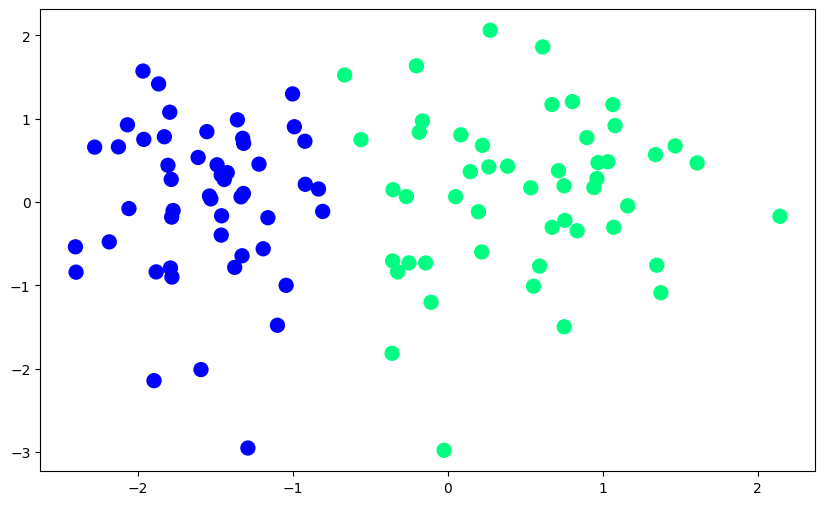

In [15]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [16]:
def step(x):
    return 1 if x > 0 else 0

In [17]:
def perceptron(X,y):
    
    X = np.insert(X,0,1,axis=1) # adds 1 for bias to make w0 * 1 for formula, makes [2, 3] to [1, 2, 3]
    weights = np.ones(X.shape[1])
    lr = 0.1
    
    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]
        
    return weights[0],weights[1:]

In [18]:
intercept_, coef_ = perceptron(X, y)

In [19]:
coef_

array([1.25667849, 0.06766758])

In [20]:
intercept_

np.float64(1.0)

In [21]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [22]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

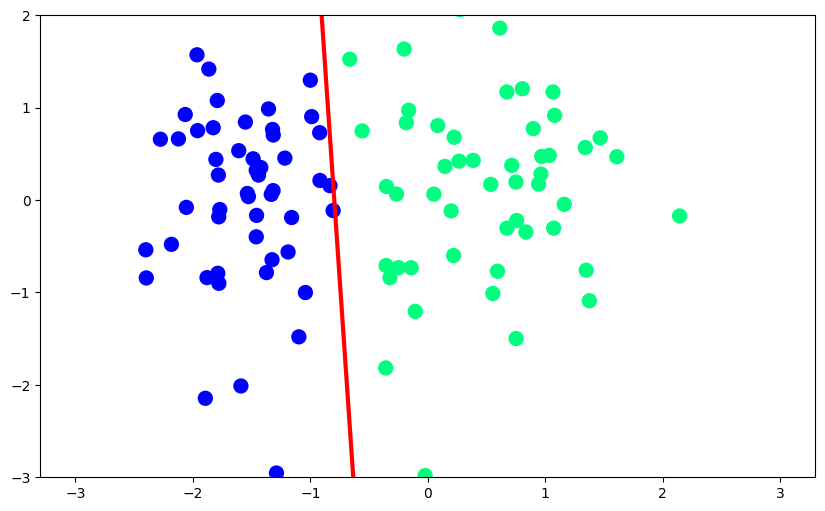

In [23]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)